## Data Loaders

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt
import pandas as pd

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = True
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 402kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.81MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.1MB/s]


## Network

In [2]:
class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            Normalize(),
            nn.Flatten(),
            nn.Linear(28*28, 50), nn.ReLU(),
            nn.Linear(50,50), nn.ReLU(),
            nn.Linear(50,50), nn.ReLU(),
            nn.Linear(50,10)
        )

    def forward(self, x):
        return self.layers(x)


model = Net().to(device)
print(model)


Net(
  (layers): Sequential(
    (0): Normalize()
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=784, out_features=50, bias=True)
    (3): ReLU()
    (4): Linear(in_features=50, out_features=50, bias=True)
    (5): ReLU()
    (6): Linear(in_features=50, out_features=50, bias=True)
    (7): ReLU()
    (8): Linear(in_features=50, out_features=10, bias=True)
  )
)


## a. IBP for training

In [3]:
def input_box(x, eps):
  lb = (x - eps).clamp(0, 1)
  ub = (x + eps).clamp(0, 1)
  return lb, ub

In [4]:
def ibp_forward(model, lb, ub, skip_last_layer=False):
  if skip_last_layer:
    layers = model.layers[:-1]
  else:
    layers = model.layers
  for layer in layers:
    # monotonic layers
    if isinstance(layer, (Normalize, nn.Flatten, nn.ReLU)):
      lb = layer(lb)
      ub = layer(ub)
    # affine layers
    else:
      center = (ub + lb) /2
      r = (ub - lb) /2
      center = F.linear(center, layer.weight, layer.bias) # W c + b
      r = F.linear(r, layer.weight.abs()) # |W| r
      lb = center - r
      ub = center + r
  return lb, ub


In [5]:
def worst_case_logits(model, x, y, eps):
  """
  returns zhat: zhat[i,j] is upper bound on how far
  class j's score can get ahead of true class y[i] for any input in eps-box.
  """
  lb, ub = input_box(x, eps)
  lb, ub = ibp_forward(model, lb, ub, True)

  W = model.layers[-1].weight
  b = model.layers[-1].bias
  batch_size = x.shape[0]

  zhat = torch.zeros(batch_size, 10, device=x.device)

  for i in range(batch_size):
    center = (ub[i] + lb[i]) /2
    r = (ub[i] - lb[i]) /2

    diff_w = W - W[y[i]]
    diff_b = b - b[y[i]]
    zhat[i] = diff_w @ center + diff_b + diff_w.abs() @ r

  return zhat

In [6]:
def get_eps_kappa(epoch):
  progress = min(epoch / 10, 1.0) # change until 10 epoch, hold afterwards
  eps_train = 0.1 * progress # 0 -> 0.1
  kappa = 1.0 - 0.5 * progress # 1 -> 0.5
  return eps_train, kappa

In [7]:
def train_model(model, num_epochs=20, mode="ibp"):
  optimizer = optim.Adam(model.parameters(), lr=1e-3)  # following appendix A
  lr_decay = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 18], gamma=0.1)
  num_batches = len(train_loader)
  eps_train, kappa = 0.0, 1.0

  if use_cuda:
    torch.cuda.synchronize()
  start = time.time()

  for epoch in range(num_epochs):
    model.train()
    sum_loss, sum_clean, sum_robust = 0.0, 0.0, 0.0
    for batch_idx, (imgs, labels) in enumerate(train_loader):
      imgs, labels = imgs.to(device), labels.to(device)
      clean_loss = F.cross_entropy(model(imgs), labels)

      if mode == "ibp":
        eps_train, kappa = get_eps_kappa(epoch + batch_idx / num_batches)
        zhat = worst_case_logits(model, imgs, labels, eps_train)
        robust_loss = F.cross_entropy(zhat, labels)
        loss = kappa * clean_loss + (1 - kappa) * robust_loss
        sum_robust += robust_loss.item()
      else:
        loss = clean_loss

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      sum_loss += loss.item()
      sum_clean += clean_loss.item()

    lr_decay.step()
    msg = f"[{mode}] epoch {epoch+1:2d}/{num_epochs} loss {sum_loss/num_batches:.4f} clean {sum_clean/num_batches:.4f}"
    if mode == "ibp":
      msg += f" robust {sum_robust/num_batches:.4f} eps {eps_train:.3f} kappa {kappa:.3f}"
    print(msg)

  if use_cuda:
    torch.cuda.synchronize()
  return time.time() - start

In [8]:
torch.manual_seed(0)
standard_model = Net().to(device)
standard_time = train_model(standard_model, mode="standard")
print(f"standard training time: {standard_time:.1f}s")

[standard] epoch  1/20 loss 0.3466 clean 0.3466
[standard] epoch  2/20 loss 0.1481 clean 0.1481
[standard] epoch  3/20 loss 0.1103 clean 0.1103
[standard] epoch  4/20 loss 0.0916 clean 0.0916
[standard] epoch  5/20 loss 0.0750 clean 0.0750
[standard] epoch  6/20 loss 0.0660 clean 0.0660
[standard] epoch  7/20 loss 0.0568 clean 0.0568
[standard] epoch  8/20 loss 0.0510 clean 0.0510
[standard] epoch  9/20 loss 0.0455 clean 0.0455
[standard] epoch 10/20 loss 0.0425 clean 0.0425
[standard] epoch 11/20 loss 0.0387 clean 0.0387
[standard] epoch 12/20 loss 0.0350 clean 0.0350
[standard] epoch 13/20 loss 0.0356 clean 0.0356
[standard] epoch 14/20 loss 0.0296 clean 0.0296
[standard] epoch 15/20 loss 0.0285 clean 0.0285
[standard] epoch 16/20 loss 0.0110 clean 0.0110
[standard] epoch 17/20 loss 0.0072 clean 0.0072
[standard] epoch 18/20 loss 0.0060 clean 0.0060
[standard] epoch 19/20 loss 0.0045 clean 0.0045
[standard] epoch 20/20 loss 0.0043 clean 0.0043
standard training time: 163.7s


In [9]:
torch.manual_seed(0)
ibp_model = Net().to(device)
ibp_time = train_model(ibp_model, mode="ibp")
print(f"IBP training time: {ibp_time:.1f}s")

[ibp] epoch  1/20 loss 0.3948 clean 0.3507 robust 1.9356 eps 0.010 kappa 0.950
[ibp] epoch  2/20 loss 0.2526 clean 0.1753 robust 1.2361 eps 0.020 kappa 0.900
[ibp] epoch  3/20 loss 0.2433 clean 0.1502 robust 0.9012 eps 0.030 kappa 0.850
[ibp] epoch  4/20 loss 0.2546 clean 0.1407 robust 0.7932 eps 0.040 kappa 0.800
[ibp] epoch  5/20 loss 0.2811 clean 0.1408 robust 0.7642 eps 0.050 kappa 0.750
[ibp] epoch  6/20 loss 0.3171 clean 0.1451 robust 0.7709 eps 0.060 kappa 0.700
[ibp] epoch  7/20 loss 0.3620 clean 0.1539 robust 0.7940 eps 0.070 kappa 0.650
[ibp] epoch  8/20 loss 0.4141 clean 0.1625 robust 0.8330 eps 0.080 kappa 0.600
[ibp] epoch  9/20 loss 0.4747 clean 0.1747 robust 0.8801 eps 0.090 kappa 0.550
[ibp] epoch 10/20 loss 0.5454 clean 0.1880 robust 0.9400 eps 0.100 kappa 0.500
[ibp] epoch 11/20 loss 0.5667 clean 0.1970 robust 0.9365 eps 0.100 kappa 0.500
[ibp] epoch 12/20 loss 0.5432 clean 0.1974 robust 0.8889 eps 0.100 kappa 0.500
[ibp] epoch 13/20 loss 0.5263 clean 0.1965 robust 0.

### PGD attack

In [10]:
# reuse HW3
def clip_box(x, delta):
    # Make x + delta an image in [0, 1]. This never increases |delta_i|.
    return (x + delta).clamp(0, 1) - x

def input_grad(model, x, delta, y):
    delta = delta.detach().requires_grad_(True)
    loss = F.cross_entropy(model(x + delta), y, reduction="sum")
    (grad,) = torch.autograd.grad(loss, delta)
    return grad.detach()

def pgd_linf(model, x, y, eps, alpha, steps, rand_init=True):
    # implement L-infinity PGD (use input_grad and clip_box)
    delta = torch.zeros_like(x)
    if rand_init:
        delta = (torch.rand_like(x) - 0.5) * 2 * eps # [0,1] -> [-1,1] -> [-eps, eps]
    delta = clip_box(x, delta)
    adv_x = x + delta
    for _ in range(steps):
        grad = input_grad(model, x, adv_x - x, y)
        adv_x = adv_x + alpha * torch.sign(grad)
        delta = torch.clamp(adv_x - x, -eps, eps)
        adv_x = x + clip_box(x, delta)
    return adv_x.detach()

In [11]:
def evaluate(model, eps=0.1, steps=50, restarts=2):
    model.eval()
    torch.manual_seed(0)  # the same random starts of the attacks for each model, so the results are comparable

    n, clean_correct, pgd_correct = 0, 0, 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            clean = model(x).argmax(1) == y
        robust = clean.clone()

        for _ in range(restarts):
            x_adv = pgd_linf(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)
            with torch.no_grad():
                robust &= model(x_adv).argmax(1) == y

        clean_correct += clean.sum().item()
        pgd_correct += robust.sum().item()
        n += len(y)
    return 100 * clean_correct / n, 100 * pgd_correct / n

In [12]:
print("Standard:", evaluate(standard_model))

Standard: (97.85, 8.55)


In [13]:
print("Robust:", evaluate(ibp_model))

Robust: (94.55, 85.85)


In [24]:
test_eps = 1/255
print("eps=",test_eps)
print("Standard:", evaluate(standard_model, eps=test_eps))
print("Robust:", evaluate(ibp_model, eps=test_eps))

eps= 0.00392156862745098
Standard: (97.85, 97.17)
Robust: (94.55, 94.3)


In [26]:
test_eps = 2/255
print("eps=",test_eps)
print("Standard:", evaluate(standard_model, eps=test_eps))
print("Robust:", evaluate(ibp_model, eps=test_eps))

eps= 0.00784313725490196
Standard: (97.85, 96.3)
Robust: (94.55, 94.01)


In [27]:
test_eps = 8/255
print("eps=",test_eps)
print("Standard:", evaluate(standard_model, eps=test_eps))
print("Robust:", evaluate(ibp_model, eps=test_eps))

eps= 0.03137254901960784
Standard: (97.85, 83.47)
Robust: (94.55, 92.64)


In [28]:
test_eps = 16/255
print("eps=",test_eps)
print("Standard:", evaluate(standard_model, eps=test_eps))
print("Robust:", evaluate(ibp_model, eps=test_eps))

eps= 0.06274509803921569
Standard: (97.85, 37.77)
Robust: (94.55, 90.18)


In [25]:
test_eps = 32/255
print("eps=",test_eps)
print("Standard:", evaluate(standard_model, eps=test_eps))
print("Robust:", evaluate(ibp_model, eps=test_eps))

eps= 0.12549019607843137
Standard: (97.85, 2.4)
Robust: (94.55, 80.44)


b. Verified Accuracy

In [16]:
@torch.no_grad()
def box_verify(model, x, y, eps):
  lb, ub = input_box(x, eps)
  lb, ub = ibp_forward(model, lb, ub)
  lb_true = lb.gather(1, y[:, None]).squeeze(1) #picks column y[i] in each row i
  mask_true = ub.scatter(1, y[:, None], float("-inf")) #set true class to -inf
  ub_other = mask_true.max(1).values # take max of other classes
  return lb_true > ub_other

In [17]:
def find_adv(model, x, y, eps, steps=100, restarts=3):
    x_best = x.clone()
    fooled = torch.zeros(len(y), dtype=torch.bool, device=x.device)
    for _ in range(restarts):
        x_adv = pgd_linf(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)
        with torch.no_grad():
            new = (model(x_adv).argmax(1) != y) & ~fooled #misclassified now and not fooled by earlier restart
        x_best[new] = x_adv[new]
        fooled = torch.where(fooled, fooled, new) # takes fooled if True else new
    return x_best, fooled

In [20]:
eps_list = [round(0.01 * k, 2) for k in range(1,11)]
N_SHOW = 5
records = []
adv_store = {}

In [21]:
ibp_model.eval()
for eps in eps_list:
  torch.manual_seed(0)
  n = n_ver = n_fals = 0
  kept = []
  for x, y in test_loader:
    x, y = x.to(device), y.to(device)
    ver = box_verify(ibp_model, x, y, eps)
    with torch.no_grad():
      wrong = ibp_model(x).argmax(1) != y
    todo = ~ver & ~wrong # attack not verified & not misclassified
    fals = wrong.clone()
    if todo.any():
      x_adv, fooled = find_adv(ibp_model, x[todo], y[todo], eps)
      idx = todo.nonzero().squeeze(1)
      fals[idx[fooled]] = True
      if len(kept) < N_SHOW and fooled.any():
        with torch.no_grad():
          p_adv = ibp_model(x_adv[fooled]).argmax(1)
        for xo, xa, yy, pp in zip(x[todo][fooled], x_adv[fooled], y[todo][fooled], p_adv):
          if len(kept) < N_SHOW:
            kept.append((xo.cpu(), xa.cpu(), yy.item(), pp.item()))
    n += y.numel(); n_ver += ver.sum().item(); n_fals += fals.sum().item()
  adv_store[eps] = kept
  records.append({"eps": eps, "verified acc (%)": 100 * n_ver / n,
                  "PGD acc (%)": 100 * (n - n_fals) / n,
                  "unknown (%)": 100 * (n - n_ver - n_fals) / n})

results_b = pd.DataFrame(records)
results_b.set_index("eps").round(2)


,verified acc (%),PGD acc (%),unknown (%)
eps,,,
0.01,93.07,93.88,0.81
0.02,91.70,93.27,1.57
0.03,90.12,92.70,2.58
0.04,87.98,91.91,3.93
0.05,85.65,91.31,5.66
0.06,82.76,90.39,7.63
0.07,79.50,89.29,9.79
0.08,74.87,88.22,13.35
0.09,70.20,87.07,16.87


In [22]:
def show_adv(eps, k=6):
  ex = adv_store[eps][:k]
  if not ex:
    print(f"eps={eps}: no adversarial example found")
    return
  fig, axes = plt.subplots(3, len(ex), figsize=(2 * len(ex), 6), squeeze=False)
  for j, (xo, xa, yy, pp) in enumerate(ex):
    axes[0, j].imshow(xo.squeeze(), cmap="gray")
    axes[0, j].set_title(f"label {yy}")
    axes[1, j].imshow(xa.squeeze(), cmap="gray")
    axes[1, j].set_title(f"pred {pp}")
    axes[2, j].imshow((xa - xo).squeeze(), cmap="bwr", vmin=-eps, vmax=eps)
  for ax in axes.flat:
    ax.axis("off")
  fig.suptitle(f"eps = {eps}  (rows: original, adversarial, perturbation)")
  plt.show()

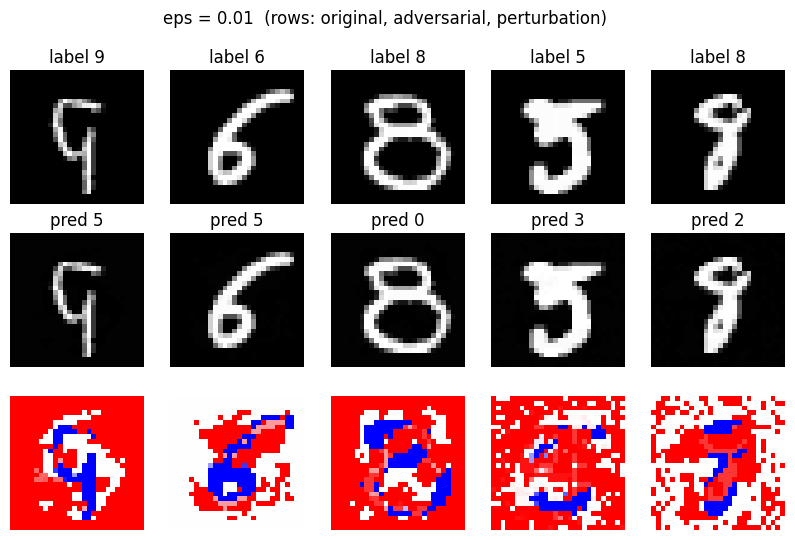

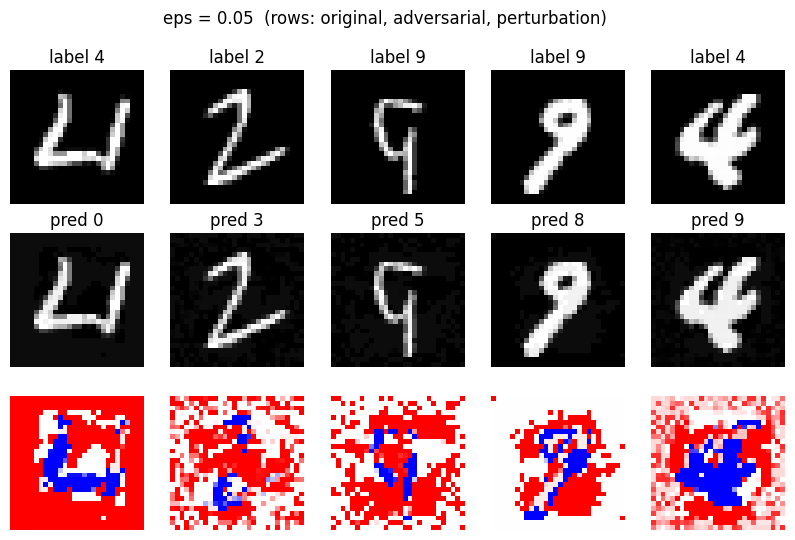

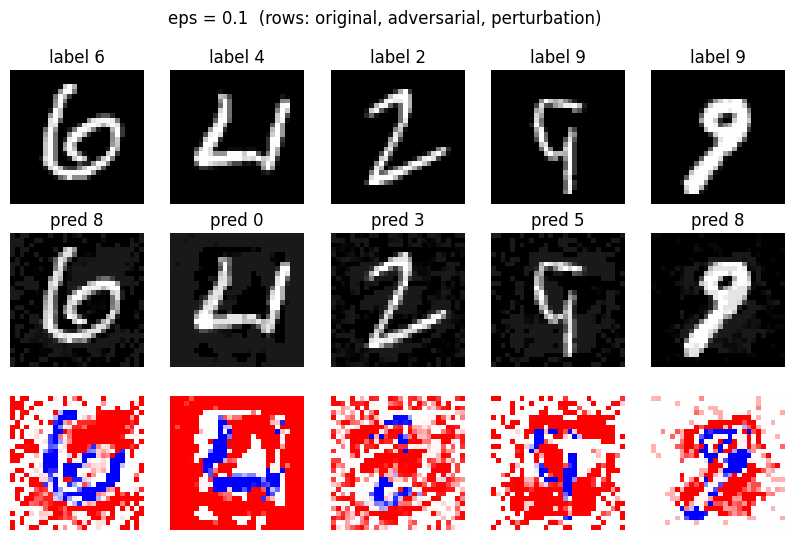

In [23]:
for eps in [0.01, 0.05, 0.1]:
  show_adv(eps)